# peptide-lloq-scatterplots
1.7.25

This is for the MagNet MMCC dataset. 

In [1]:
import pandas as pd
import numpy as np 

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

pd.set_option('display.max_rows', 500)

#### Configs

In [2]:
knn_report_path="../quants-reports/ljh-report-knn-lib.csv"
rowmeans_report_path="../quants-reports/ljh-report-rowmeans-lib.csv"
mf_report_path="../quants-reports/ljh-report-missForest-lib.csv"
diann_report_path="../quants-reports/ljh-report-diann-lib-v1.csv"

thresh=0.1

#### Read in the Skyline quants reports 

In [3]:
to_drop = ["Peptide", "Protein", "Protein Name", "Limit Of Quantification", "Turning Point"]
to_drop1 = ["Peptide", "Protein", "Protein Name", "Turning Point"]

# Read in 
rm_report = pd.read_csv(rowmeans_report_path, low_memory=False)
knn_report = pd.read_csv(knn_report_path, low_memory=False)
mf_report = pd.read_csv(mf_report_path, low_memory=False)
diann_report = pd.read_csv(diann_report_path, low_memory=False)

# Remove the decoy proteins
decoy_arr1 = rm_report["Protein Name"] == "Decoys"
rm_report = rm_report[~decoy_arr1]

decoy_arr2 = knn_report["Protein Name"] == "Decoys"
knn_report = knn_report[~decoy_arr2]

decoy_arr3 = mf_report["Protein Name"] == "Decoys"
mf_report = mf_report[~decoy_arr3]

decoy_arr4 = diann_report["Protein Name"] == "Decoys"
diann_report = diann_report[~decoy_arr4]

# Remove the extraneous columns
rm_report = rm_report.drop(columns=to_drop1)
knn_report = knn_report.drop(columns=to_drop)
mf_report = mf_report.drop(columns=to_drop)
diann_report = diann_report.drop(columns=to_drop1)

# Reindex
rm_report.index = rm_report["Peptide Modified Sequence"]
rm_report = rm_report.drop(columns=["Peptide Modified Sequence"])

knn_report.index = knn_report["Peptide Modified Sequence"]
knn_report = knn_report.drop(columns=["Peptide Modified Sequence"])

mf_report.index = mf_report["Peptide Modified Sequence"]
mf_report = mf_report.drop(columns=["Peptide Modified Sequence"])

diann_report.index = diann_report["Peptide Modified Sequence"]
diann_report = diann_report.drop(columns=["Peptide Modified Sequence"])

#### Drop duplicates

In [4]:
knn_report = knn_report.drop_duplicates(keep="first")
rm_report = rm_report.drop_duplicates(keep="first")
mf_report = mf_report.drop_duplicates(keep="first")
diann_report = diann_report.drop_duplicates(keep="first")

print(knn_report.shape)
print(rm_report.shape)
print(mf_report.shape)
print(diann_report.shape)

(31117, 44)
(31117, 44)
(31117, 44)
(28291, 44)


#### Subset to only the common peptides 

In [5]:
diann_prots = set(diann_report.index)
knn_prots = set(knn_report.index)
mf_prots = set(mf_report.index)
rm_prots = set(rm_report.index)

inter = set.intersection(diann_prots, knn_prots, mf_prots, rm_prots)

# Subset the quants reports to only the shared peptides
diann_report = diann_report.loc[list(inter)]
knn_report = knn_report.loc[list(inter)]
mf_report = mf_report.loc[list(inter)]
rm_report = rm_report.loc[list(inter)]

#### Sort the quants report dataframes 

In [6]:
knn_report = knn_report.loc[sorted(knn_report.index)]
rm_report = rm_report.loc[sorted(rm_report.index)]
mf_report = mf_report.loc[sorted(mf_report.index)]
diann_report = diann_report.loc[sorted(diann_report.index)]

print(knn_report.shape)
print(rm_report.shape)
print(mf_report.shape)
print(diann_report.shape)

(28291, 44)
(28291, 44)
(28291, 44)
(28291, 44)


#### Extract the LLOQs 
And create a new dataframe. 

In [7]:
diann_lod = np.array(diann_report["Limit Of Detection"])
knn_lod = np.array(knn_report["Limit Of Detection"])
rm_lod = np.array(rm_report["Limit Of Detection"])
mf_lod = np.array(mf_report["Limit Of Detection"])

# Manually set zero as the lowest possible value, to address a known Skyline issue
diann_lod[diann_lod < 0.0] = 0.0
knn_lod[knn_lod < 0.0] = 0.0
rm_lod[rm_lod < 0.0] = 0.0
mf_lod[diann_lod < 0.0] = 0.0

lod_df = pd.DataFrame(columns=["Peptide", "DIA-NN", "Row Means", "MissForest", "KNN"])
lod_df["Peptide"] = diann_report.index
lod_df["DIA-NN"] = diann_lod
lod_df["Row Means"] = rm_lod
lod_df["MissForest"] = mf_lod
lod_df["KNN"] = knn_lod

#### Get the pairwise difference in LOD between DIA-NN and each method

In [8]:
rm_delta = lod_df["DIA-NN"] - lod_df["Row Means"]
mf_delta = lod_df["DIA-NN"] - lod_df["MissForest"]
knn_delta = lod_df["DIA-NN"] - lod_df["KNN"]

pairwise_df = pd.DataFrame(columns=["Row \nMeans", "MissForest", "KNN"])

pairwise_df["Row \nMeans"] = rm_delta
pairwise_df["MissForest"] = mf_delta
pairwise_df["KNN"] = knn_delta

pairwise_melt = pairwise_df.melt()

#### Get the positive and negative fractions 

In [9]:
# Get the counts
rm_pos_count = np.count_nonzero(pairwise_df["Row \nMeans"] > 0)
rm_neg_count = np.count_nonzero(pairwise_df["Row \nMeans"] < 0)

mf_pos_count = np.count_nonzero(pairwise_df["MissForest"] > 0)
mf_neg_count = np.count_nonzero(pairwise_df["MissForest"] < 0)

knn_pos_count = np.count_nonzero(pairwise_df["KNN"] > 0)
knn_neg_count = np.count_nonzero(pairwise_df["KNN"] < 0)

# Get the fractions
rm_pos_frac = np.around(rm_pos_count / len(pairwise_df["Row \nMeans"]), 2)
mf_pos_frac = np.around(mf_pos_count / len(pairwise_df["MissForest"]), 2)
knn_pos_frac = np.around(knn_pos_count / len(pairwise_df["KNN"]), 2)

rm_neg_frac = 1 - rm_pos_frac
mf_neg_frac = 1 - mf_pos_frac
knn_neg_frac = 1 - knn_pos_frac

#### Replot for a single RT boundary impute method
Which we'll call Nettle. This is for our HUPO talk. 

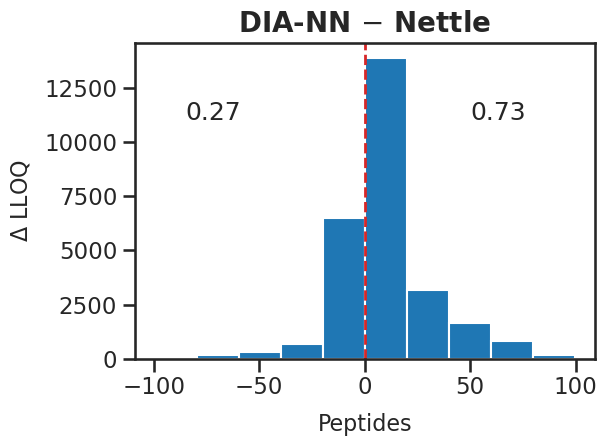

In [10]:
fig, ax = plt.subplots()

sns.histplot(
    data=pairwise_df, 
    x="KNN", 
    fill=True,
    bins=10,
    color="#1f77b4",
    alpha=1.0, 
)
plt.xlabel("Peptides", labelpad=10, size=16)
plt.ylabel("$Δ$ LLOQ", labelpad=8, size=16)
plt.title("DIA-NN $-$ Nettle", pad=8, size=20, fontweight="bold")
plt.axvline(x=0, color="#d62728", linewidth=2, linestyle="--")
plt.text(50, 11000, s=knn_pos_frac)
plt.text(-85, 11000, s=knn_neg_frac)

plt.tight_layout()
#plt.savefig("../figures/lloq-pairwise-v2.png", dpi=250, bbox_inches="tight")

---
## Add a traditional boxplot

#### Filter by high R squared values
Is this cheating, in the sense that we can only do it for an MMCC experiment? 

In [11]:
# rm_report_filt = rm_report[rm_report["R Squared"] > thresh]
# knn_report_filt = knn_report[knn_report["R Squared"] > thresh]
# mf_report_filt = mf_report[mf_report["R Squared"] > thresh]
# diann_report_filt = diann_report[diann_report["R Squared"] > thresh]

rm_lod = list(rm_report["Limit Of Detection"])
knn_lod = list(knn_report["Limit Of Detection"])
mf_lod = list(mf_report["Limit Of Detection"])
diann_lod = list(diann_report["Limit Of Detection"])

#### Add some padding to the end of each LOD array 

In [12]:
max_len = np.max([len(rm_lod), len(knn_lod), len(mf_lod), len(diann_lod)])

toadd_rm = max_len - len(rm_lod)
toadd_knn = max_len - len(knn_lod)
toadd_mf = max_len - len(mf_lod)
toadd_diann = max_len - len(diann_lod)

toadd_rm = np.zeros(toadd_rm)
toadd_rm[:] = np.nan
rm_lod = rm_lod + list(toadd_rm)

toadd_knn = np.zeros(toadd_knn)
toadd_knn[:] = np.nan
knn_lod = knn_lod + list(toadd_knn)

toadd_mf = np.zeros(toadd_mf)
toadd_mf[:] = np.nan
mf_lod = mf_lod + list(toadd_mf)

toadd_diann = np.zeros(toadd_diann)
toadd_diann[:] = np.nan
diann_lod = diann_lod + list(toadd_diann)

#### Create a new plotter dataframe 

In [13]:
plotter1 = pd.DataFrame(columns=["Row \nMeans", "Nettle", "MissForest", "Unimputed"])

plotter1["Row \nMeans"] = rm_lod
plotter1["Nettle"] = knn_lod
plotter1["MissForest"] = mf_lod
plotter1["Unimputed"] = diann_lod

#### Artificially set the min LLOQ
This is a Skyline bug: for some reason you sometimes get LLOQs < 0.0

In [14]:
plotter1[plotter1 < 0] = 0.0

plotter1_melt = plotter1.melt()

#### Custom palette

In [15]:
cmap_cust = list(plt.cm.tab10.colors)
cmap_cust[0] = cmap_cust[7]
cmap_cust[1] = cmap_cust[4]
cmap_cust = tuple(cmap_cust)

#### Get LOD boxplot

In [16]:
# var_order = ["DIA-NN", "Nettle"]

# fig, ax = plt.subplots(figsize=(6.5,5))

# sns.boxplot(
#     data=plotter1_melt, 
#     x="variable",
#     y="value",
#     fill=True, 
#     saturation=1.0, 
#     palette=cmap_cust,
#     order=var_order,
#     fliersize=1.0,
# )

# plt.xlabel("", labelpad=12, size=20)
# plt.ylabel("Lower Limit of \nDetection", labelpad=6, size=20)

# plt.ylim(-5, 100)
# #ax.tick_params(axis='x', colors=['black', 'red'])
# #plt.legend(edgecolor="black", prop={"size":16}, bbox_to_anchor=(1.01, 1.05))

# plt.tight_layout()
# #plt.savefig("../figures/peptide-lloq-boxplot-v3.png", dpi=250, bbox_inches="tight")

#### Try to plot side-by-side

In [17]:
# var_order = ["Unimputed", "Nettle"]

# fig, ax = plt.subplots(1, 2, figsize=(12,6))

# # The LLOQ boxplot
# sns.boxplot(
#     data=plotter1_melt, 
#     x="variable",
#     y="value",
#     fill=True, 
#     saturation=1.0, 
#     palette=cmap_cust,
#     order=var_order,
#     fliersize=1.0,
#     ax=ax[0]
# )
# ax[0].set_xlabel("", labelpad=12, size=20)
# ax[0].set_ylabel("LLOQ", labelpad=6, size=20)
# ax[0].set_ylim(-5, 105)

# # The LLOQ pairwise deltas plot 
# sns.histplot(
#     data=pairwise_df, 
#     x="KNN", 
#     fill=True,
#     bins=10,
#     color="#1f77b4",
#     alpha=1.0, 
#     ax=ax[1]
# )
# ax[1].set_xlabel("Peptides", labelpad=10, size=20)
# ax[1].set_ylabel("$Δ$ LLOQ", labelpad=8, size=20)
# ax[1].set_title("Unimputed $-$ Nettle", pad=8, size=20, fontweight="bold")
# ax[1].axvline(x=0, color="#d62728", linewidth=2, linestyle="--")
# ax[1].text(50, 11000, s=knn_pos_frac)
# ax[1].text(-85, 11000, s=knn_neg_frac)

# plt.tight_layout()
# #plt.savefig("../figures/lloq-figure-combined.png", dpi=250, bbox_inches="tight")
# #plt.savefig("../figures/lloq-figure-combined.pdf", bbox_inches="tight")

---
## Think I actually want these as seperate plots 

#### The boxplot

/tmp/ipykernel_507889/817057641.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


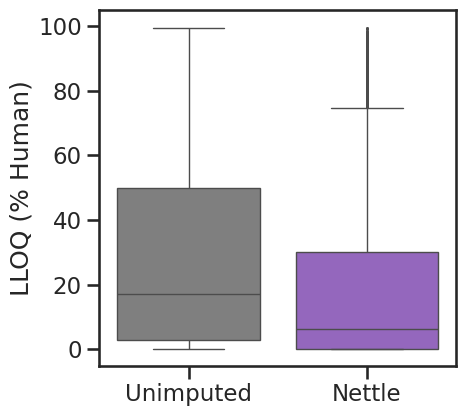

In [32]:
var_order = ["Unimputed", "Nettle"]

fig, ax = plt.subplots(figsize=(5,4.5))

sns.boxplot(
    data=plotter1_melt, 
    x="variable",
    y="value",
    fill=True, 
    saturation=1.0, 
    palette=cmap_cust,
    order=var_order,
    fliersize=1.0,
)
ax.set_xlabel("", labelpad=8, size=20)
ax.set_ylabel("LLOQ (% Human)", labelpad=3, size=18)
ax.set_ylim(-5, 105)

plt.tight_layout()
#plt.savefig("../figures/lloq-figure-combined.png", dpi=250, bbox_inches="tight")
plt.savefig("../figures/lloq-boxplot-v1.pdf", bbox_inches="tight")

#### Get the means/medians
There are a lot of outliers; mean might not be the best metric to look at. 

In [19]:
nettle_mean = np.nanmean(plotter1["Nettle"])
nettle_median = np.nanmedian(plotter1["Nettle"])
unimputed_mean = np.nanmean(plotter1["Unimputed"])
unimputed_median = np.nanmedian(plotter1["Unimputed"])

print(nettle_median)
print(unimputed_median)

6.44
17.08


#### The distributions plot

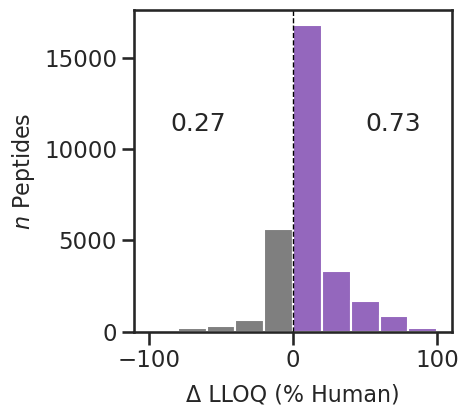

In [35]:
var_order = ["Unimputed", "Nettle"]

fig, ax = plt.subplots(figsize=(5,4.5))

sns.histplot(
    data=pairwise_df, 
    x="KNN", 
    fill=True,
    bins=5,
    color="#7f7f7f",
    alpha=1.0,
    binrange=(-100, 0)
)
sns.histplot(
    data=pairwise_df, 
    x="KNN", 
    fill=True,
    bins=5,
    color="#9467bd",
    alpha=1.0,
    binrange=(0, 100)
)
#ax.set_xlabel("LLOQ Unimputed $-$\n LLOQ Nettle", labelpad=8, size=16)
ax.set_xlabel("Δ LLOQ (% Human)", labelpad=8, size=16)
ax.set_ylabel("$n$ Peptides", labelpad=5, size=16)
#ax.set_title("Unimputed $-$ Nettle", pad=8, size=20, fontweight="bold")
ax.axvline(x=0, color="black", linewidth=1, linestyle="--")
ax.text(50, 11000, s=knn_pos_frac)
ax.text(-85, 11000, s=knn_neg_frac)

plt.tight_layout()
#plt.savefig("../figures/lloq-figure-combined.png", dpi=250, bbox_inches="tight")
plt.savefig("../figures/lloq-figure-hist.pdf", bbox_inches="tight")

---
## Scratch 

In [21]:
lod_df = lod_df.sample(frac=1)
lod_df.head(100)

,Peptide,DIA-NN,Row Means,MissForest,KNN
19455,QLVKPEQLPIYTAPPLQSK,18.6940,37.82,13.08,14.16
1468,ALPGTPVASSQPR,41.8590,0.80,0.00,0.10
4275,DLGIFWLNAAETWVDISSNTAGK,75.0000,56.26,56.26,56.26
27155,WLTIQSGEQPYK,20.8080,14.88,1.15,1.20
17187,MTPLSFIPGAK,30.0000,7.00,1.00,3.00
3351,C[+57]PNDC[+57]HSR,7.0000,12.65,13.20,12.71
4485,DNC[+57]APESIEFPVSEAR,0.1000,0.00,0.00,0.00
8488,GFEAAVAAGAK,16.4090,21.75,2.20,2.41
6198,EQC[+57]TAGAGC[+57]C[+57]LQPATGR,1.0000,0.00,0.00,0.00
13619,LEHEYIHNFK,64.3840,0.00,0.70,7.00


In [22]:
lod_df[lod_df["Peptide"] == "DQLQTFSEEHP"]

,Peptide,DIA-NN,Row Means,MissForest,KNN
